In [ ]:
from pathlib import Path
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import ListedColormap
import matplotlib

from europa_eutectic.gaia_sim import GaiaSim
from europa_eutectic.util import colors


AUX_BASE = Path("../../data")
shell_visc_sims = [json_path for json_path in Path(AUX_BASE / "shell_visc").glob("*.json")]
shell_complex_rheo_sims = [json_path for json_path in Path(AUX_BASE / "shell_complex_rheo").glob("*.json")]
constK_varA_sims = [json_path for json_path in Path(AUX_BASE / "shell_thermal_cond_expan" / "constK_varA").glob("*.json")]
varK_constA_sims = [json_path for json_path in Path(AUX_BASE  / "shell_thermal_cond_expan" / "varK_constA").glob("*.json")]
varK_varA_sims = [json_path for json_path in Path(AUX_BASE    / "shell_thermal_cond_expan" / "varK_varA").glob("*.json")]
shell_tidal_sims = [json_path for json_path in Path(AUX_BASE / "shell_tidal").glob("*.json")]

base_cmap = sns.color_palette("icy_moon_2", as_cmap = True) # My custom colormap

In [4]:
shell_complex_rheo_sims

[PosixPath('../../../../../auxillary/shell_complex_rheo/Europa_D30km_eta2e-04_data.json'),
 PosixPath('../../../../../auxillary/shell_complex_rheo/Europa_D40km_eta2e-04_data.json'),
 PosixPath('../../../../../auxillary/shell_complex_rheo/Europa_D50km_eta2e-04_data.json'),
 PosixPath('../../../../../auxillary/shell_complex_rheo/Europa_D60km_eta2e-04_data.json'),
 PosixPath('../../../../../auxillary/shell_complex_rheo/Europa_D20km_eta2e-04_data.json')]

# A big set of temp profiles

#### See others for inspiration
#### Maybe just plot them all then mess with it by hand?

In [10]:
shell_visc_sims_sorted = sorted(shell_visc_sims, key=lambda x: int(x.stem.split("_")[-3].replace("D", "").replace("km", "")))
shell_visc_sims_sorted_v2 = sorted(shell_visc_sims_sorted, key=lambda x: int(x.stem.split("_")[-2].replace("eta1e+", "")))

shell_visc_sims = [GaiaSim.load_from_json(sim_path) for sim_path in shell_visc_sims_sorted_v2]
sim_dict = {12.0: [], 13.0: [], 14.0: [], 15.0: []}

for sim in shell_visc_sims:
    if sim.eta_ref in sim_dict.keys():
        sim_dict[sim.eta_ref].append(sim)


reg2_169_RR0.987186_P0.02.grid  PATH /scratch/ws25/byrn_wi-europa_eutectic/Europa_D20km_eta1e+12/.
reg2_169_RR0.987186_P0.02.grid  PATH /scratch/ws25/byrn_wi-europa_eutectic/Europa_20km_eta1e+12_small_test/.
reg2_169_RR0.987186_P0.02.grid  PATH /scratch/ws25/byrn_wi-europa_eutectic/Europa_20km_eta1e+12/.
reg2_270_RR0.980779_P0.02.grid  PATH /scratch/ws25/byrn_wi-europa_eutectic/Europa_30km_eta1e+12/.
reg2_270_RR0.980779_P0.02.grid  PATH /scratch/ws25/byrn_wi-europa_eutectic/Europa_D30km_eta1e+12/.
reg2_270_RR0.974372_P0.02.grid  PATH /scratch/ws25/byrn_wi-europa_eutectic/Europa_40km_eta1e+12/.
reg2_270_RR0.974372_P0.02.grid  PATH /scratch/ws25/byrn_wi-europa_eutectic/Europa_D40km_eta1e+12/.
reg2_270_RR0.967965_P0.02.grid  PATH /scratch/ws25/byrn_wi-europa_eutectic/Europa_50km_eta1e+12/.
reg2_270_RR0.967965_P0.02.grid  PATH /scratch/ws25/byrn_wi-europa_eutectic/Europa_D50km_eta1e+12/.
reg2_270_RR0.961558_P0.02.grid  PATH /scratch/ws25/byrn_wi-europa_eutectic/Europa_60km_eta1e+12/.
reg2_

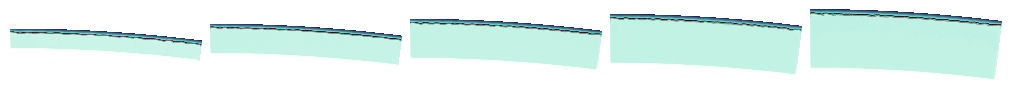

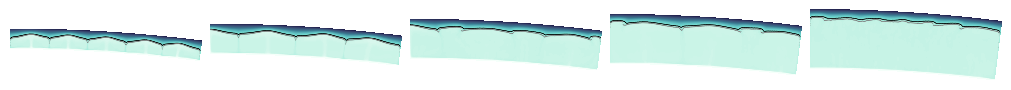

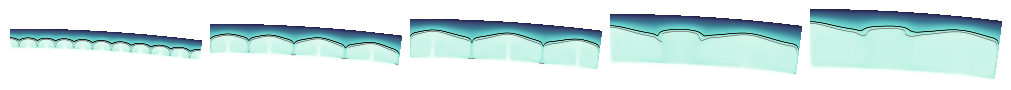

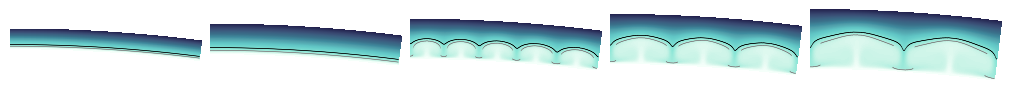

In [40]:
sns.set_context("paper", font_scale=1.0) 


for key in sim_dict.keys():
    sns.set_context("paper", font_scale=1.0) 
    fig, axes = plt.subplots(1, 5, figsize=(2 * 5, 5), constrained_layout=True)
    for ax, sim in zip(axes, sim_dict[key]):
        # Load simulation    
        # Ensure it's squeezed to 2D
        field_data = sim.avg_temp_2d.squeeze()
        coords = np.array(sim.last_output.grid.shellCoords)
        y_coords = coords[:, :, 0] # Assuming Y is first dim based on previous code
        x_coords = coords[:, :, 1]
    
        levels = np.linspace(np.min(field_data), np.max(field_data), 256)

        # Plot Contourf
        cont = ax.contourf(x_coords, y_coords, field_data, levels=levels, cmap=base_cmap, extend="neither")
        for eutectic, color in zip(sim.eutectics, ("black", "grey")):
    
            zol_broadcast = np.broadcast_to(np.asarray(eutectic.depth_to_eutectic).reshape(1, -1), sim.depth_2d.shape)

            diff = np.abs(sim.depth_2d.squeeze() - zol_broadcast)
            best_row_indices = np.argmin(diff, axis=0)


            clean_mask = np.zeros_like(sim.depth_2d.squeeze(), dtype=int)
            cols = np.arange(clean_mask.shape[1])
            clean_mask[best_row_indices, cols] = 1

            ax.contour(x_coords, y_coords, clean_mask, levels=[0.5], colors=color, linewidths=0.3)

        ax.set_aspect('equal')
        ax.axis('off') # Hide axis numbers for cleaner look
        plt.savefig(f"shell_visc_sims_grid_10^{key}.png", dpi=700, transparent=True)
    plt.show()



In [6]:
key = lambda x: int(x.stem.split("_")[1].replace("D", "").replace("km", ""))

complex_sims_list = sorted(constK_varA_sims, key=key) + sorted(varK_constA_sims, key=key) + sorted(varK_varA_sims, key=key) + sorted(shell_complex_rheo_sims, key=key) + sorted(shell_tidal_sims, key=key)
complex_sims = [GaiaSim.load_from_json(sim_path) for sim_path in complex_sims_list]

complex_sim_dict = {"constK_varA": [], "varK_constA": [], "varK_varA": [], "shell_complex_rheo": [], "shell_tidal": []}

for sim in complex_sims:
    if sim.parent_dir.name in complex_sim_dict.keys():
        complex_sim_dict[sim.parent_dir.name].append(sim)

reg2_231_RR0.980779_P0.02.grid  PATH /scratch/ws/m2/byrn_wi-europa_eutectic/var_thermal/varK_constA/Europa_D30km_eta1e+13/.
reg2_270_RR0.974372_P0.02.grid  PATH /scratch/ws/m2/byrn_wi-europa_eutectic/var_thermal/varK_constA/Europa_D40km_eta1e+13/.
reg2_270_RR0.967965_P0.02.grid  PATH /scratch/ws/m2/byrn_wi-europa_eutectic/var_thermal/varK_constA/Europa_D50km_eta1e+13/.
reg2_270_RR0.961558_P0.02.grid  PATH /scratch/ws/m2/byrn_wi-europa_eutectic/var_thermal/varK_constA/Europa_D60km_eta1e+13/.
reg2_139_RR0.987186_P0.02.grid  PATH /scratch/ws/m2/byrn_wi-europa_eutectic/var_thermal/varK_varA/Europa_D20km_eta1e+13/.
reg2_231_RR0.980779_P0.02.grid  PATH /scratch/ws/m2/byrn_wi-europa_eutectic/var_thermal/varK_varA/Europa_D30km_eta1e+13/.
reg2_270_RR0.974372_P0.02.grid  PATH /scratch/ws25/byrn_wi-europa_eutectic/varA_varK/Europa_40km_eta1e+13/.
reg2_270_RR0.967965_P0.02.grid  PATH /scratch/ws/m2/byrn_wi-europa_eutectic/var_thermal/varK_varA/Europa_D50km_eta1e+13/.
reg2_270_RR0.961558_P0.02.grid

In [7]:
complex_sim_dict

{'constK_varA': [GaiaSimcaseID='Europa_D20km_eta1e+13', 
              parent_dir='/plp_user/byrn_wi/scr1/shell_thermal_cond_expan/constK_varA', 
              "Shell thickness"=20000.00 (m),
              "log_10(eta_ref)"=13.00 log_10(Pa s),
              Ra=19307853.09746666, 
              final_time=63.5099 Myr),
  GaiaSimcaseID='Europa_D30km_eta1e+13', 
              parent_dir='/plp_user/byrn_wi/scr1/shell_thermal_cond_expan/constK_varA', 
              "Shell thickness"=30000.00 (m),
              "log_10(eta_ref)"=13.00 log_10(Pa s),
              Ra=63422023.86201102, 
              final_time=21.6397 Myr),
  GaiaSimcaseID='Europa_D40km_eta1e+13', 
              parent_dir='/plp_user/byrn_wi/scr1/shell_thermal_cond_expan/constK_varA', 
              "Shell thickness"=40000.00 (m),
              "log_10(eta_ref)"=13.00 log_10(Pa s),
              Ra=146181606.4293653, 
              final_time=21.3795 Myr),
  GaiaSimcaseID='Europa_D50km_eta1e+13', 
              parent_dir='/p

constK_varA


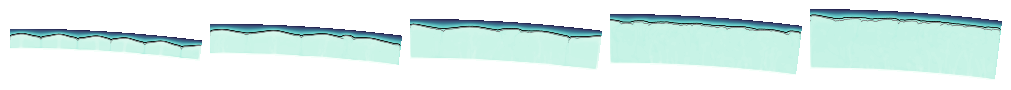

varK_constA


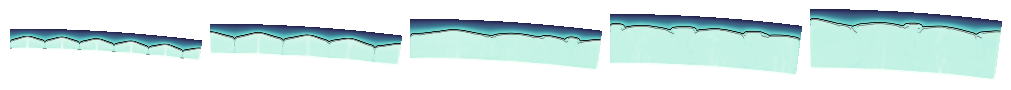

varK_varA


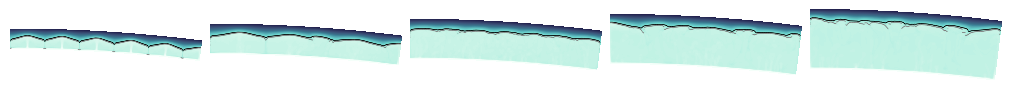

shell_complex_rheo


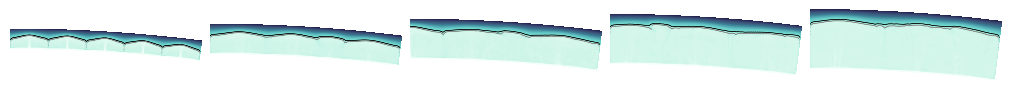

shell_tidal


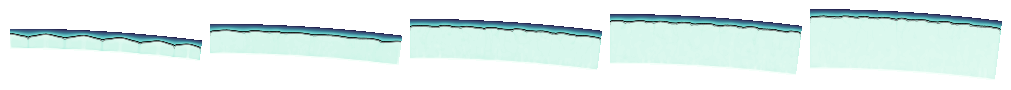

In [16]:
sns.set_context("paper", font_scale=1.0) 


for key in complex_sim_dict.keys():
    sns.set_context("paper", font_scale=1.0) 
    fig, axes = plt.subplots(1, 5, figsize=(2 * 5, 5), constrained_layout=True)
    for ax, sim in zip(axes, complex_sim_dict[key]):
        # Load simulation    
        # Ensure it's squeezed to 2D
        field_data = sim.avg_temp_2d.squeeze()
        coords = np.array(sim.last_output.grid.shellCoords)
        y_coords = coords[:, :, 0] # Assuming Y is first dim based on previous code
        x_coords = coords[:, :, 1]
    
        levels = np.linspace(np.min(field_data), np.max(field_data), 256)

        # Plot Contourf
        cont = ax.contourf(x_coords, y_coords, field_data, levels=levels, cmap=base_cmap, extend="neither")
        for eutectic, color in zip(sim.eutectics, ("black", "grey")):
    
            zol_broadcast = np.broadcast_to(np.asarray(eutectic.depth_to_eutectic).reshape(1, -1), sim.depth_2d.shape)

            diff = np.abs(sim.depth_2d.squeeze() - zol_broadcast)
            best_row_indices = np.argmin(diff, axis=0)


            clean_mask = np.zeros_like(sim.depth_2d.squeeze(), dtype=int)
            cols = np.arange(clean_mask.shape[1])
            clean_mask[best_row_indices, cols] = 1

            ax.contour(x_coords, y_coords, clean_mask, levels=[0.5], colors=color, linewidths=0.3)
        ax.set_aspect('equal')
        ax.axis('off') # Hide axis numbers for cleaner look
        plt.savefig(f"complex_sims_grid_{key}.png", dpi=700, transparent=True)
    print(key)
    plt.show()

# Deformation Field

In [ ]:
complex_rheo_sims = [GaiaSim.load_from_json(simpath) for simpath in complex_sims_list if "rheo" in str(simpath)]
complex_rheo_sims

[GaiaSimcaseID='Europa_D20km_eta2e-04', 
             parent_dir='/plp_user/byrn_wi/scr1/shell_complex_rheo', 
             "Shell thickness"=20000.00 (m),
             "log_10(eta_ref)"=13.00 log_10(Pa s),
             Ra=19307853.09746666, 
             final_time=157.403 Myr),
 GaiaSimcaseID='Europa_D30km_eta2e-04', 
             parent_dir='/plp_user/byrn_wi/scr1/shell_complex_rheo', 
             "Shell thickness"=30000.00 (m),
             "log_10(eta_ref)"=13.00 log_10(Pa s),
             Ra=63422023.86201102, 
             final_time=33.029 Myr),
 GaiaSimcaseID='Europa_D40km_eta2e-04', 
             parent_dir='/plp_user/byrn_wi/scr1/shell_complex_rheo', 
             "Shell thickness"=40000.00 (m),
             "log_10(eta_ref)"=13.00 log_10(Pa s),
             Ra=146181606.4293653, 
             final_time=19.7659 Myr),
 GaiaSimcaseID='Europa_D50km_eta2e-04', 
             parent_dir='/plp_user/byrn_wi/scr1/shell_complex_rheo', 
             "Shell thickness"=50000.00 (m),
  

[-0.5  0.5  1.5  2.5]


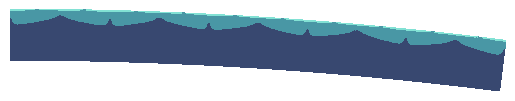

[-0.5  0.5  1.5  2.5]


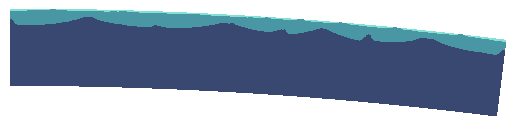

[-0.5  0.5  1.5  2.5]


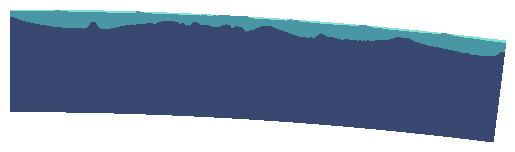

[-0.5  0.5  1.5  2.5]


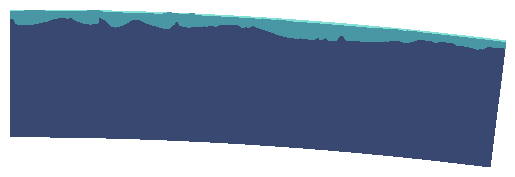

[-0.5  0.5  1.5  2.5]


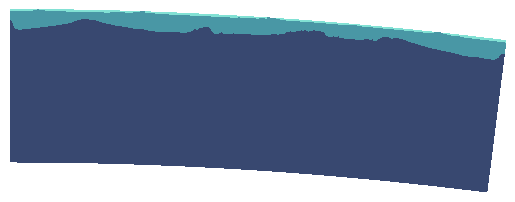

In [26]:
sns.set_context("paper", font_scale=1.0) 
icy_palette = ListedColormap(base_cmap(np.linspace(0.15, 0.82, 3)))


for sim in complex_rheo_sims: # 0 is bottom (diffusion), 2 near stagnant lid boundary middle (gbs), 1 is dislocation 
    
    field_data = sim.avg_deformation_2d.copy()
    mask0 = field_data == 1.0
    mask1 = field_data == 2.0
    field_data[mask0] = 2.0
    field_data[mask1] = 1.0

    unique_vals = np.unique(field_data)
    levels = np.arange(unique_vals.min()-0.5, unique_vals.max() + 0.6, 1.0) 
    
    print(levels)

    coords = np.array(sim.last_output.grid.shellCoords)
    y_coords = coords[:, :, 0] # Assuming Y is first dim based on previous code
    x_coords = coords[:, :, 1]
    
    # Plot Contourf
    deform = plt.contourf(x_coords, y_coords, field_data,
                       levels=levels, cmap=icy_palette,
                       extend="neither")
    
    plt.gca().set_aspect('equal') # I think this line is necessary
    plt.gca().set_axis_off()
    plt.savefig(f"supp_{sim.caseID}_mfield.png", transparent = True, dpi = 500)
    plt.show()

# Colorbars

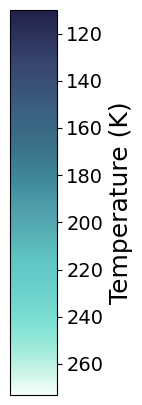

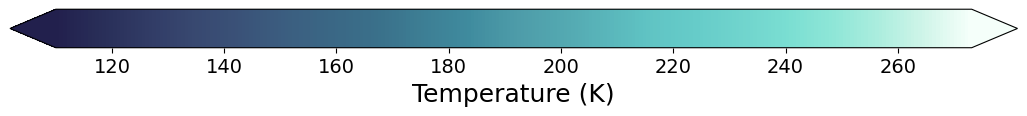

In [ ]:
fig, ax = plt.subplots(figsize=(0.6, 5))  # skinny figure for bar only

norm = matplotlib.colors.Normalize(vmin=110, vmax=273.15)
sm = matplotlib.cm.ScalarMappable(norm=norm, cmap=base_cmap)
sm.set_array([])  # needed for older matplotlib

cbar = fig.colorbar(sm, 
                    cax=ax, 
                    orientation='vertical',
                    fraction= 0.03,
                    aspect = 35,
                    pad=0.02)
cbar.set_label("Temperature (K)", fontsize = 18)
cbar.ax.tick_params(labelsize=14)
cbar.ax.invert_yaxis()
fig.canvas.draw()
plt.savefig(f"colorbars/vert_temp_bar.png", dpi=700, transparent=True, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(13, 0.5))  # skinny figure for bar only
cbar = fig.colorbar(sm, 
                    cax=ax, 
                    orientation='horizontal',
                    pad=0.04,
                    extend='both')
cbar.set_label("Temperature (K)", fontsize = 18)
cbar.ax.tick_params(labelsize=14)
#cbar.ax.invert_xaxis()
fig.canvas.draw()
plt.savefig(f"colorbars/horz_temp_bar.png", dpi=700, transparent=True, bbox_inches="tight")
plt.show()